### Run this notebook online

[![Open in Colab](https://img.shields.io/badge/Open_in-Colab-F9AB00?logo=googlecolab&logoColor=F9AB00)](https://colab.research.google.com/github/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/CIFAR10%20DiT.ipynb)
[![Open in Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://www.kaggle.com/kernels/welcome?src=https%3A%2F%2Fgithub.com%2Fhosein-fanai%2FContinual-Learning-with-Diffusion-Vision-Transformers%2Fblob%2Fmain%2Ffiles%2Fnotebooks%2FCIFAR10%2520DiT.ipynb)
[![Launch Binder](https://img.shields.io/badge/launch-binder-F5793A?logo=jupyter&logoColor=white)](https://mybinder.org/v2/gh/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/main?urlpath=lab%2Ftree%2Ffiles%2Fnotebooks%2FCIFAR10%20DiT.ipynb)

- **Google Colab:** open the notebook, select a GPU for training under **Runtime > Change runtime type**, then choose **Run all**.
- **Kaggle:** sign in and import the notebook, enable **Internet**, select a **GPU** accelerator for training, then **Run all**.
- **Binder:** opens a temporary CPU JupyterLab session. Use it to inspect the notebook or run small checks; full training needs more resources.
- **[Studio Lab](https://studiolab.sagemaker.aws/import/github/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/CIFAR10%20DiT.ipynb) (existing accounts only):** start a runtime, copy the notebook to your project, select a Python **3.11–3.13** kernel, and set `RUNTIME = "studiolab"` in the first code cell before **Run all**. For CPU, also set `CUDA = False`.

The **first code cell** finds or downloads the repository and prepares TensorFlow **2.20** / Keras **3.11.2** before project imports. If setup requests a restart, restart the kernel and run all again. For another hosted Jupyter service, set `RUNTIME = "hosted"` (`CUDA = False` for CPU or compatible provider-managed CUDA). Locally, select the project TensorFlow kernel.

Launch links open the published GitHub `main` version; publish this notebook and its setup files together before using them. For a notebook that has not been published, upload its `.ipynb` file to Colab or Kaggle instead. GPU availability depends on the provider. Save checkpoints and results before a temporary session ends.

See the [hosted runtime guide](https://github.com/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/thesis/README.md#hosted-runtimes) for setup and import details.


In [ ]:
"""Prepare a notebook checkout and runtime before importing scientific packages.

This canonical first-cell source is copied into maintained notebooks and generated
HPO notebooks. Edit REVISION/RUNTIME/CUDA before execution when needed. Existing
checkouts are reused without fetching; only missing setup code is downloaded.
ROOT is the selected absolute pathlib.Path; RUNTIME_PACKAGES maps package names
to installed version strings. Preparation may clone/install under the selected
policy and changes cwd/import paths through files.notebooks.init.prepare_notebook.
"""
from pathlib import Path
from urllib.request import urlopen


CHECKOUT_NAME = "Continual-Learning-with-Diffusion-Vision-Transformers"
REPOSITORY = f"https://github.com/hosein-fanai/{CHECKOUT_NAME}.git"
REVISION = "main"
RUNTIME = "local"  # Use "hosted" for another online service, or "local" to verify only.
CUDA = None  # False: CPU or managed CUDA; True: retain CUDA pip dependencies.

_locations = (Path.cwd(), *Path.cwd().parents, Path.cwd() / CHECKOUT_NAME, 
              Path("/kaggle/working") / CHECKOUT_NAME, Path("/content") / CHECKOUT_NAME)
_initializer = next((path / "files" / "notebooks" / "init.py" for path in _locations
                     if (path / "files" / "notebooks" / "init.py").is_file()), None)
_url = f"https://raw.githubusercontent.com/hosein-fanai/{CHECKOUT_NAME}/{REVISION}/files/notebooks/init.py"
_setup = {"__name__": "notebook_setup", "__file__": str(_initializer or _url)}
with (_initializer.open("rb") if _initializer else urlopen(_url, timeout=30)) as _file:
    exec(compile(_file.read(), _setup["__file__"], "exec"), _setup)
ROOT, RUNTIME_PACKAGES = _setup["prepare_notebook"](
    checkout_name=CHECKOUT_NAME, 
    repository=REPOSITORY, 
    revision=REVISION, 
    runtime=RUNTIME, 
    cuda=CUDA
)

Repository ready: /workspace/cifar10_dit_three_v2_20261011/source (runtime: local)
Runtime packages ready: Python 3.12.3, TensorFlow 2.20.0, Keras 3.11.2


In [3]:
from common import utils


utils.init()

## Experiment settings


In [4]:
epochs = 50
val_freq = 5

## CIFAR10 data


In [5]:
from common.dataloader import load_cifar10, get_dataset


x_train, y_train, _, _, x_test, y_test = load_cifar10(
    indices=None, 
    validation_ratio=0.0, 
    verbose=0
)

trainset = get_dataset(x_train, y_train.reshape(-1))
valset = get_dataset(x_test, y_test.reshape(-1), shuffle_buffer=0, drop_remainder=False)

2026-10-11 11:30:25.878973: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1791718225.880230  157191 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 24576 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:13:00.0, compute capability: 8.0


## DiT denoiser


In [6]:
from diffusion.models.transformer.diffusion_transformer import DiffusionTransformer
from diffusion.models.wrapper.diffusion_model import DiffusionModel


vit = DiffusionTransformer(
    image_size=32, 
    channels=3, 
    dim=128, 
    depth=6, 
    mha_num_heads=4, 
    patchify_with_cnn=True, 
    use_refiner_cnn=False
)
model = DiffusionModel(network=vit, p_uncond=0.2)

vit.summary()

Model: "diffusion_transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ depth_0_patch_embedder          │ (None, 256, 128)       │        75,648 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_embedder           │ (None, 128)            │       128,000 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_label_embedder          │ (None, 128)            │         1,408 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_label_merger (Add) │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_1_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_2_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_3_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_4_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_5_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_6_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ unpatchifier (Functional)       │ (None, 32, 32, 3)      │        34,572 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,020,656 (7.71 MB)

 Trainable params: 1,892,620 (7.22 MB)

 Non-trainable params: 128,036 (500.28 KB)

## Optimizer


In [ ]:
from tensorflow.keras import optimizers


lr_schedule = optimizers.schedules.CosineDecay(
    initial_learning_rate=0.004923507985709955, # 5e-3
    decay_steps=epochs * len(trainset)
)

model.compile(
    optimizer=optimizers.AdamW(
        lr_schedule, 
        weight_decay=0.0006398310822142558, 
        clipnorm=5.0
    ), 
    loss="mse"
)

In [ ]:
from tensorflow.keras import callbacks

from common.callbacks.lr_logger import LrLogger

from diffusion.callbacks.image_generator import ImageGenerator


callbacks_list = [
    LrLogger(), 
    callbacks.ProgbarLogger(), 
    ImageGenerator(frequency=val_freq)
]

## Training


Epoch 1/50


2026-10-11 11:30:51.759719: I external/local_xla/xla/service/service.cc:163] XLA service 0x796abc06a910 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-11 11:30:51.759746: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA A100-SXM4-80GB, Compute Capability 8.0


2026-10-11 11:30:52.393513: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


2026-10-11 11:30:56.431936: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002


2026-10-11 11:30:57.983995: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-11 11:30:57.984317: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-11 11:30:57.984465: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-11 11:30:57.984644: I external/l

...

2026-10-11 11:33:28.935119: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 4 bytes spill stores, 4 bytes spill loads

2026-10-11 11:33:29.083680: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6', 276 bytes spill stores, 276 bytes spill loads



2026-10-11 11:33:35.665851: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


2026-10-11 11:33:36.275546: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_172', 32 bytes spill stores, 32 bytes spill loads

2026-10-11 11:33:36.340104: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_172', 32 bytes spill stores, 32 bytes spill loads



2026-10-11 11:33:36.571629: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_172', 436 bytes spill stores, 456 bytes spill loads



390/390 37s 94ms/step - noise_loss: 0.0312 - val_image_loss: 0.9933 - val_loss: 0.0615 - val_noise_loss: 0.0615 - learning_rate: 0.0048
Steps: 50/50


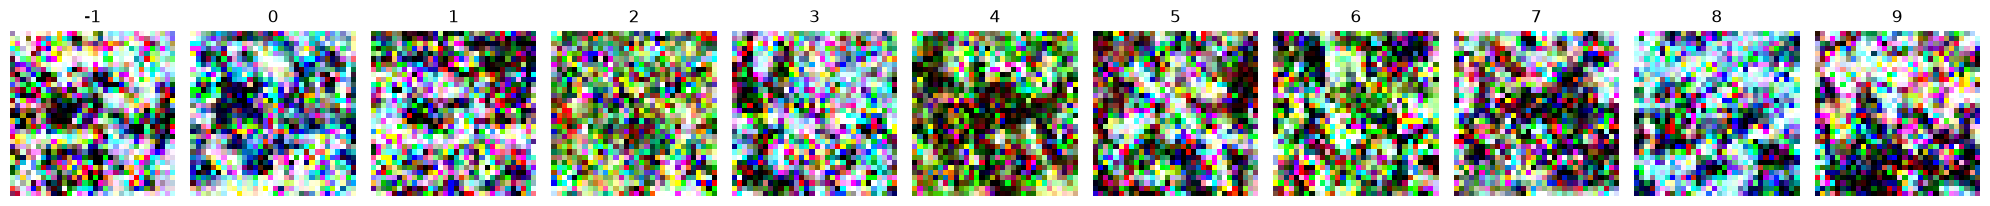

Epoch 6/50

390/390 26s 67ms/step - noise_loss: 0.0309 - learning_rate: 0.0048
Epoch 7/50

390/390 26s 67ms/step - noise_loss: 0.0308 - learning_rate: 0.0047
Epoch 8/50

390/390 26s 67ms/step - noise_loss: 0.0303 - learning_rate: 0.0046
Epoch 9/50

390/390 26s 67ms/step - noise_loss: 0.0303 - learning_rate: 0.0045
Epoch 10/50

390/390 26s 67ms/step - noise_loss: 0.0302 - val_image_loss: 0.1068 - val_loss: 0.0314 - val_noise_loss: 0.0314 - learning_rate: 0.0045
Steps: 50/50


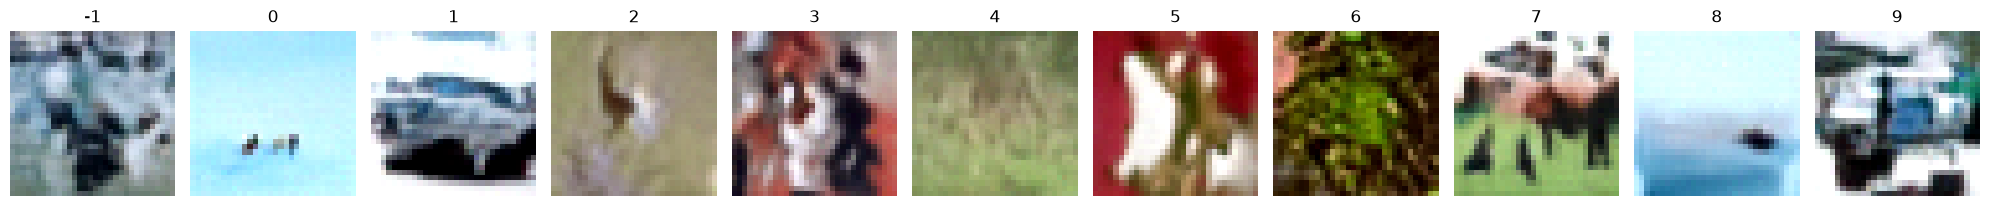

Epoch 11/50

390/390 26s 67ms/step - noise_loss: 0.0300 - learning_rate: 0.0044
Epoch 12/50

390/390 26s 67ms/step - noise_loss: 0.0298 - learning_rate: 0.0043
Epoch 13/50

390/390 26s 67ms/step - noise_loss: 0.0297 - learning_rate: 0.0041
Epoch 14/50

390/390 26s 67ms/step - noise_loss: 0.0299 - learning_rate: 0.0040
Epoch 15/50

390/390 26s 67ms/step - noise_loss: 0.0298 - val_image_loss: 0.0814 - val_loss: 0.0313 - val_noise_loss: 0.0313 - learning_rate: 0.0039
Steps: 50/50


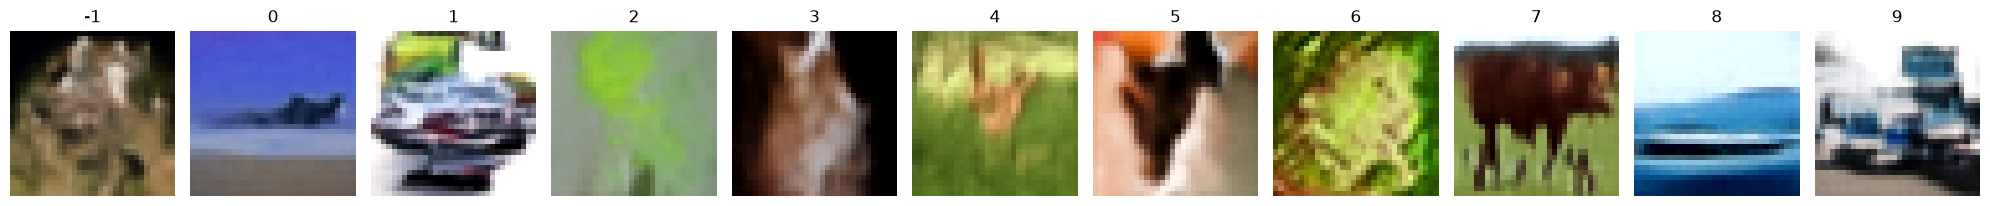

Epoch 16/50

390/390 26s 67ms/step - noise_loss: 0.0295 - learning_rate: 0.0038
Epoch 17/50

390/390 26s 67ms/step - noise_loss: 0.0294 - learning_rate: 0.0036
Epoch 18/50

390/390 26s 67ms/step - noise_loss: 0.0293 - learning_rate: 0.0035
Epoch 19/50

390/390 26s 68ms/step - noise_loss: 0.0296 - learning_rate: 0.0034
Epoch 20/50

390/390 26s 68ms/step - noise_loss: 0.0295 - val_image_loss: 0.0799 - val_loss: 0.0307 - val_noise_loss: 0.0307 - learning_rate: 0.0032
Steps: 50/50


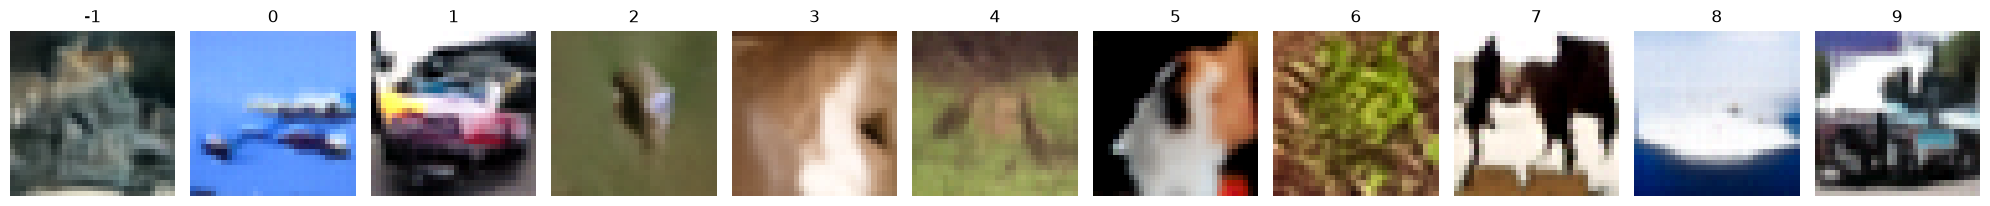

Epoch 21/50

390/390 26s 67ms/step - noise_loss: 0.0293 - learning_rate: 0.0031
Epoch 22/50

390/390 26s 67ms/step - noise_loss: 0.0292 - learning_rate: 0.0029
Epoch 23/50

390/390 26s 67ms/step - noise_loss: 0.0291 - learning_rate: 0.0028
Epoch 24/50

390/390 26s 67ms/step - noise_loss: 0.0292 - learning_rate: 0.0026
Epoch 25/50

390/390 27s 68ms/step - noise_loss: 0.0289 - val_image_loss: 0.0777 - val_loss: 0.0310 - val_noise_loss: 0.0310 - learning_rate: 0.0025
Steps: 50/50


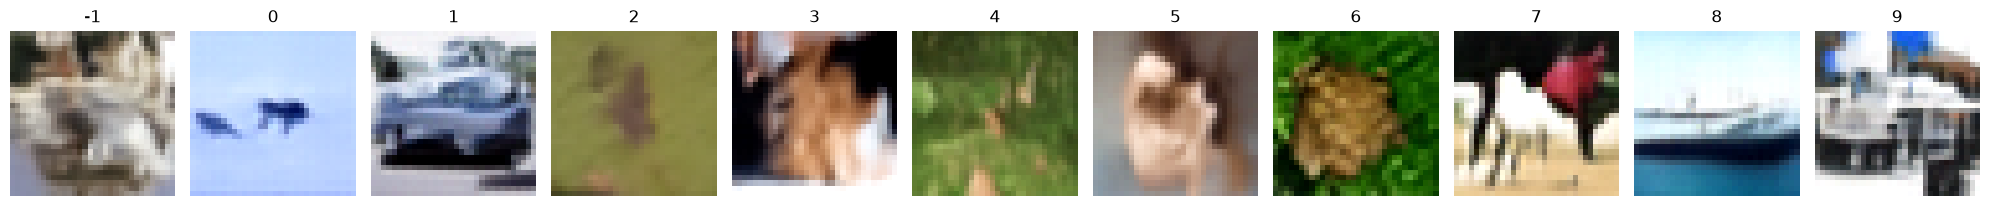

Epoch 26/50

390/390 26s 66ms/step - noise_loss: 0.0290 - learning_rate: 0.0023
Epoch 27/50

390/390 26s 67ms/step - noise_loss: 0.0291 - learning_rate: 0.0022
Epoch 28/50

390/390 26s 67ms/step - noise_loss: 0.0289 - learning_rate: 0.0020
Epoch 29/50

390/390 26s 67ms/step - noise_loss: 0.0288 - learning_rate: 0.0018
Epoch 30/50

390/390 26s 66ms/step - noise_loss: 0.0288 - val_image_loss: 0.0780 - val_loss: 0.0307 - val_noise_loss: 0.0307 - learning_rate: 0.0017
Steps: 50/50


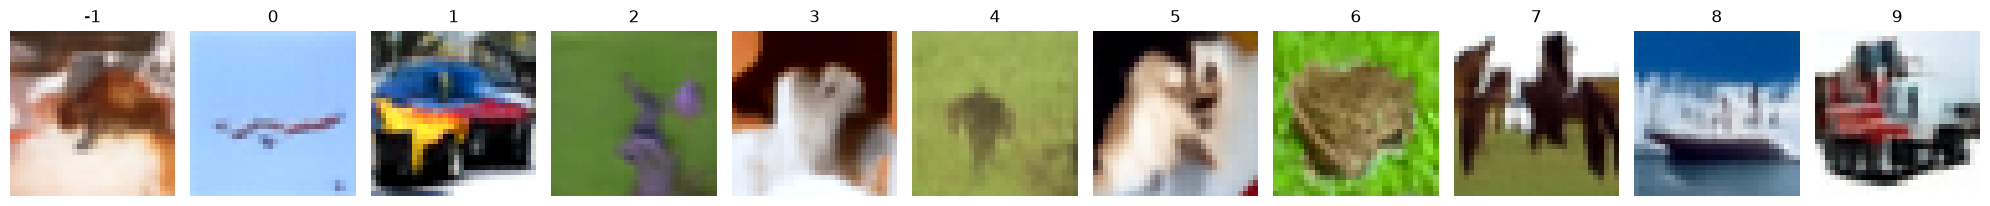

Epoch 31/50

390/390 26s 66ms/step - noise_loss: 0.0287 - learning_rate: 0.0016
Epoch 32/50

390/390 26s 66ms/step - noise_loss: 0.0285 - learning_rate: 0.0014
Epoch 33/50

390/390 26s 67ms/step - noise_loss: 0.0284 - learning_rate: 0.0013
Epoch 34/50

390/390 26s 67ms/step - noise_loss: 0.0283 - learning_rate: 0.0011
Epoch 35/50

390/390 25s 64ms/step - noise_loss: 0.0286 - val_image_loss: 0.0794 - val_loss: 0.0309 - val_noise_loss: 0.0309 - learning_rate: 0.0010
Steps: 50/50


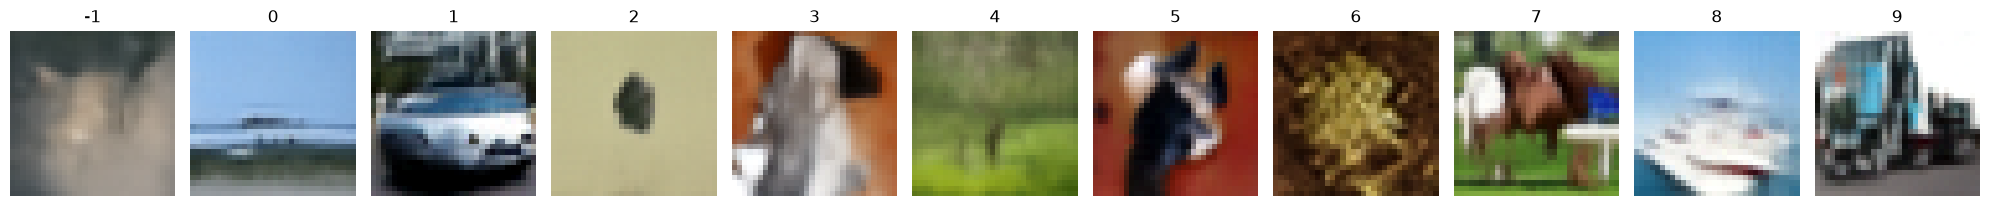

Epoch 36/50

390/390 26s 67ms/step - noise_loss: 0.0283 - learning_rate: 8.9257e-04
Epoch 37/50

390/390 26s 67ms/step - noise_loss: 0.0283 - learning_rate: 7.7657e-04
Epoch 38/50

390/390 26s 68ms/step - noise_loss: 0.0285 - learning_rate: 6.6721e-04
Epoch 39/50

390/390 26s 66ms/step - noise_loss: 0.0283 - learning_rate: 5.6494e-04
Epoch 40/50

390/390 24s 61ms/step - noise_loss: 0.0281 - val_image_loss: 0.0776 - val_loss: 0.0313 - val_noise_loss: 0.0313 - learning_rate: 4.7015e-04
Steps: 50/50


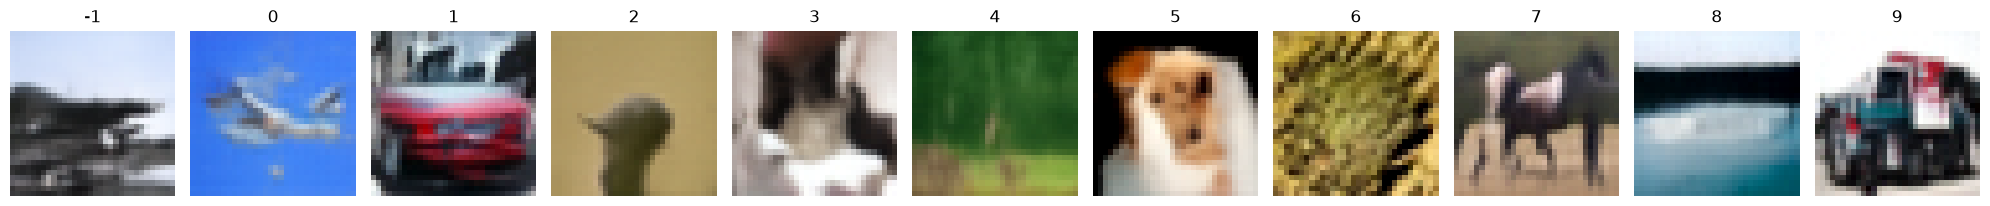

Epoch 41/50

390/390 26s 67ms/step - noise_loss: 0.0282 - learning_rate: 3.8323e-04
Epoch 42/50

390/390 26s 67ms/step - noise_loss: 0.0281 - learning_rate: 3.0450e-04
Epoch 43/50

390/390 26s 67ms/step - noise_loss: 0.0281 - learning_rate: 2.3429e-04
Epoch 44/50

390/390 26s 66ms/step - noise_loss: 0.0280 - learning_rate: 1.7287e-04
Epoch 45/50

390/390 24s 60ms/step - noise_loss: 0.0280 - val_image_loss: 0.0785 - val_loss: 0.0315 - val_noise_loss: 0.0315 - learning_rate: 1.2049e-04
Steps: 50/50


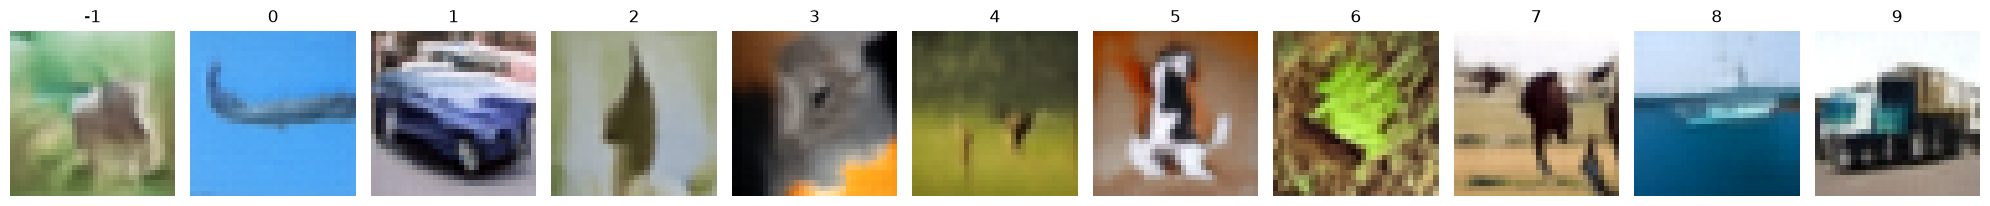

Epoch 46/50

390/390 26s 68ms/step - noise_loss: 0.0282 - learning_rate: 7.7340e-05
Epoch 47/50

390/390 26s 67ms/step - noise_loss: 0.0279 - learning_rate: 4.3604e-05
Epoch 48/50

390/390 26s 68ms/step - noise_loss: 0.0279 - learning_rate: 1.9412e-05
Epoch 49/50

390/390 25s 65ms/step - noise_loss: 0.0278 - learning_rate: 4.8577e-06
Epoch 50/50

390/390 21s 53ms/step - noise_loss: 0.0279 - val_image_loss: 0.0781 - val_loss: 0.0314 - val_noise_loss: 0.0314 - learning_rate: 0.0000e+00
Steps: 50/50


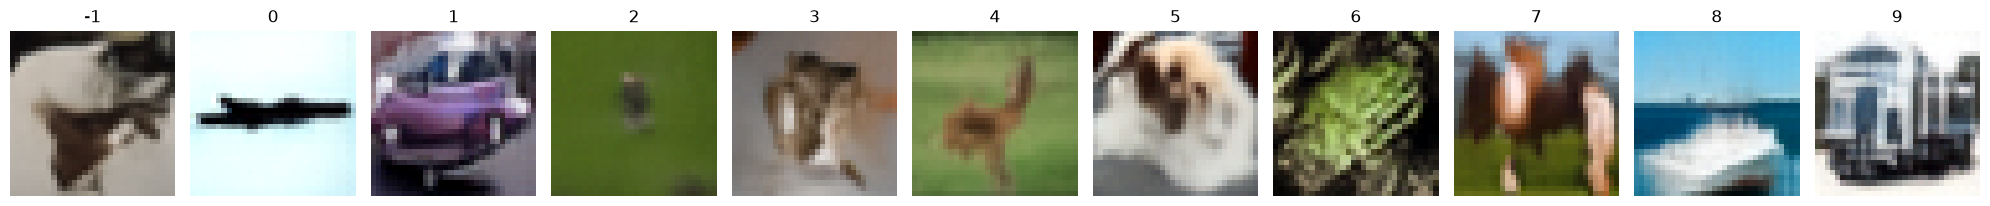

In [9]:
history = model.fit(
    trainset, 
    epochs=epochs, 
    validation_data=valset, 
    callbacks=callbacks_list, 
    validation_freq=val_freq
).history

## Save weights


In [10]:
model.save_weights("/workspace/cifar10_dit_three_v2_20261011/notebook-2/model.weights.h5")

## Evaluate EMA and raw networks


In [11]:
model.evaluate(valset, network_name="ema")

79/79 2s 25ms/step - image_loss: 0.0797 - loss: 0.0314 - noise_loss: 0.0314


[<tf.Tensor: shape=(), dtype=float32, numpy=0.03140780329704285>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.03140780329704285>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.07970429211854935>]

In [12]:
model.evaluate(valset, network_name="raw")

79/79 14s 91ms/step - image_loss: 0.0799 - loss: 0.0313 - noise_loss: 0.0313


[<tf.Tensor: shape=(), dtype=float32, numpy=0.03128323704004288>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.03128323704004288>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.07994502037763596>]

## Class-conditional samples


Steps: 1000/1000


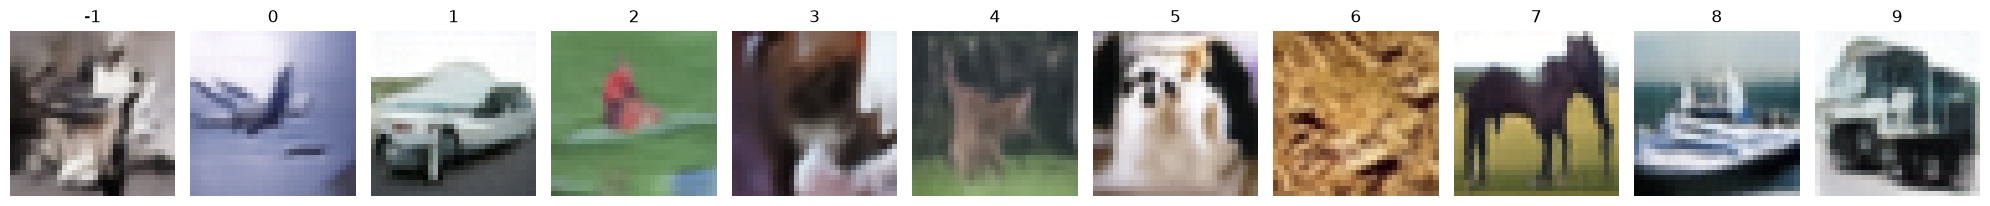

In [13]:
from common.utils import plot_images


imgs = model.sample(
    add_null_label=True, 
    scale=3., 
    eta=1., 
    steps=1_000, 
    verbose=True
)
plot_images(imgs, has_null_label=True)

Steps: 1000/1000


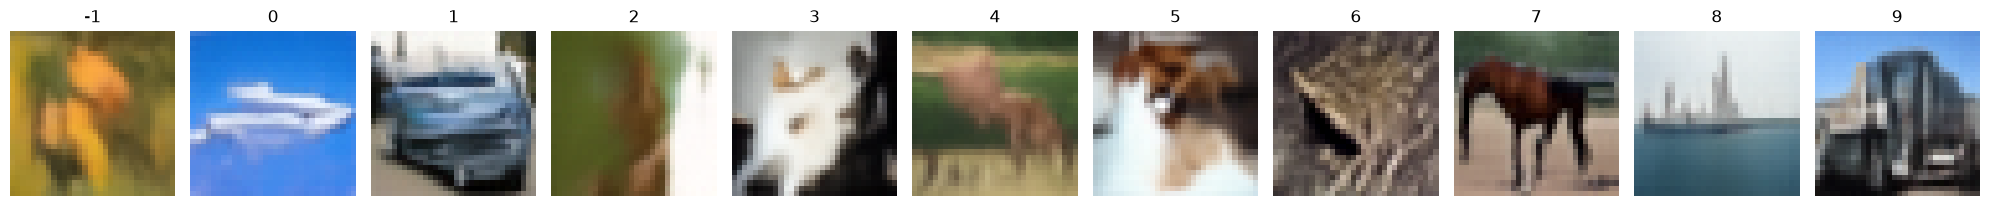

In [14]:
imgs = model.sample(
    add_null_label=True, 
    scale=3., 
    steps=1_000, 
    verbose=True
)
plot_images(imgs, has_null_label=True)

Steps: 50/50


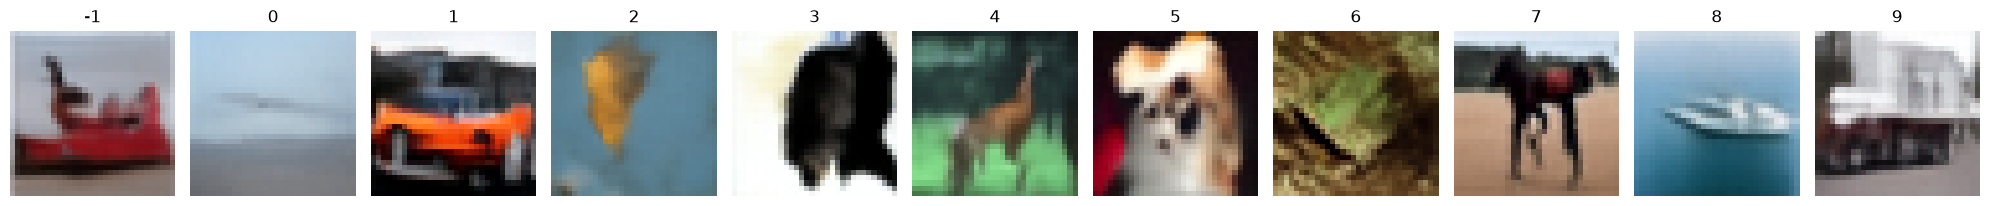

In [15]:
imgs = model.sample(
    add_null_label=True, 
    scale=3., 
    verbose=True
)
plot_images(imgs, has_null_label=True)

Steps: 50/50


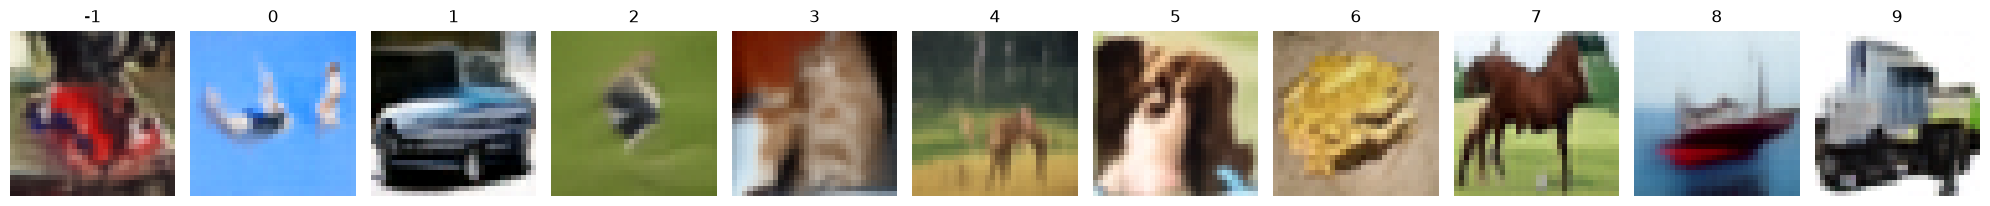

In [16]:
imgs = model.sample(
    add_null_label=True, 
    scale=4., 
    verbose=True
)
plot_images(imgs, has_null_label=True)

## Training history


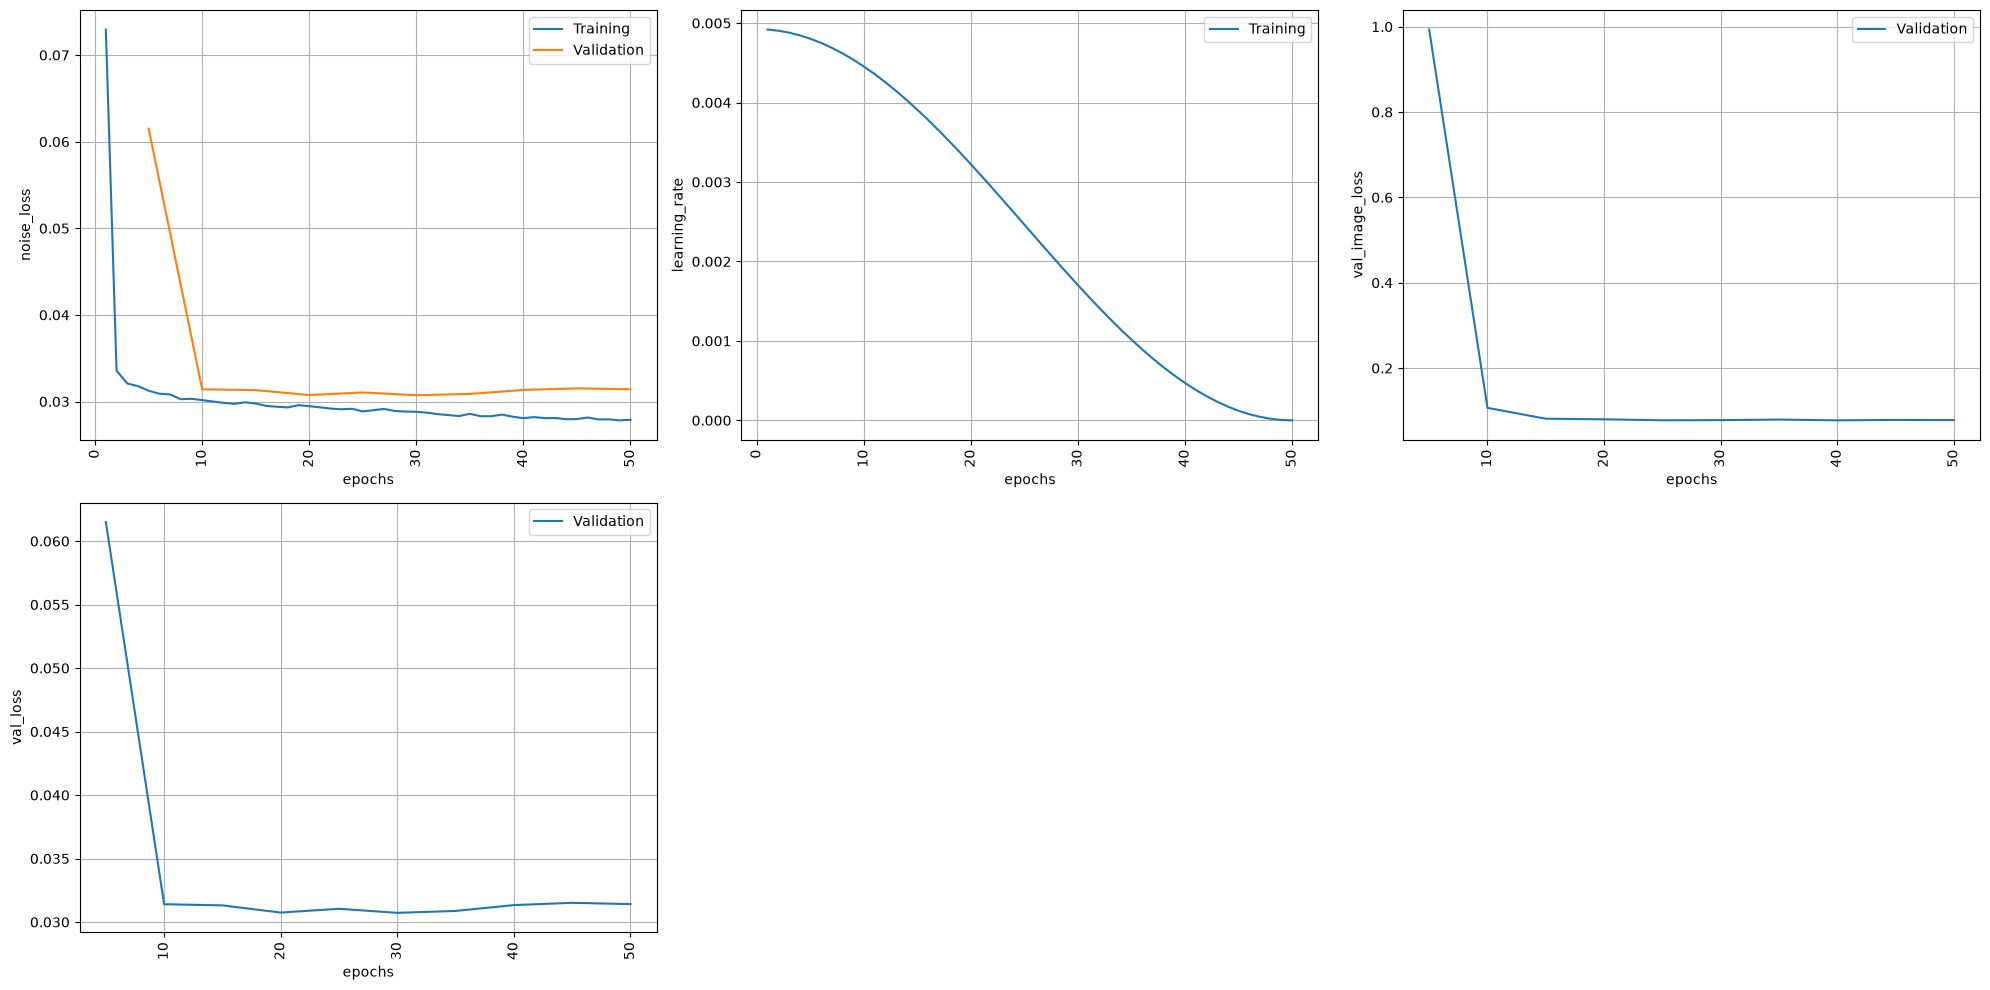

In [17]:
from common.utils import plot_history


plot_history(history, show_all_x_ticks=False)

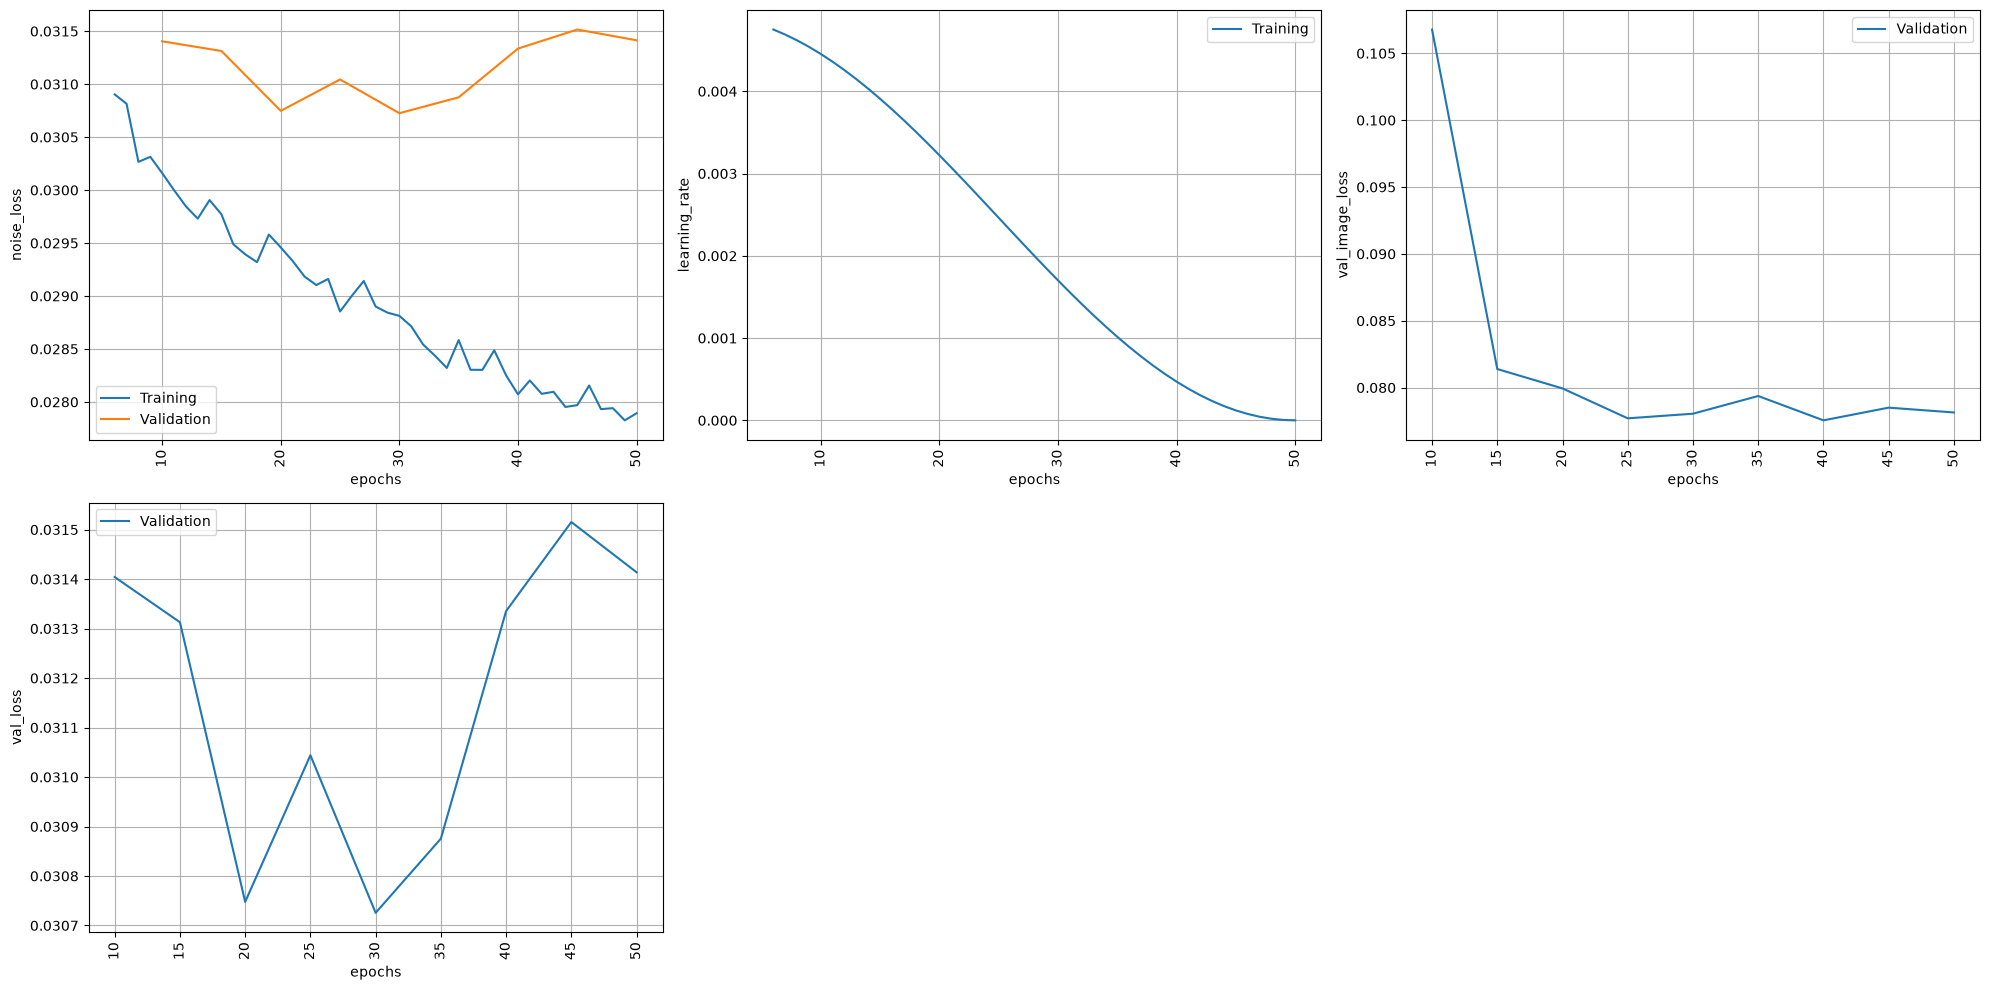

In [18]:
plot_history(history, show_all_x_ticks=False, range_=(5, None))